In [30]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os

from diffusion_mlp_cnn.models.CNN import CNNDiffusionRegressor
from diffusion_mlp_cnn.models.utils import Data

In [31]:
plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

# Load data

### Training and single-step validation data

In [32]:
size = 1925
initializations = ["gaussian", "uniform", "cosine"]
training_data = Data(
    initializations,
    path="../datasets/training_size_" + str(size) + "/training_data",
    model_type="CNN"
)
print(f"Input training data shape (N_samples, Nx): "
      f"{training_data.X_numpy.shape}")
print(f"Output training data shape (N_samples, Nx): "
      f"{training_data.Y_numpy.shape}")
print(f"Training data dtype (input, output): "
      f"({training_data.X.dtype}, {training_data.Y.dtype})")

Input training data shape (N_samples, Nx): (1925, 1, 201)
Output training data shape (N_samples, Nx): (1925, 1, 201)
Training data dtype (input, output): (torch.float32, torch.float32)


In [33]:
validation_data = Data(
    initializations,
    path="../datasets/training_size_" + str(size) + "/validation_data",
    model_type="CNN"
)
print(f"Input single step validation data shape (N_samples, Nx): "
      f"{validation_data.X_numpy.shape}")
print(f"Output single step validation data shape (N_samples, Nx): "
      f"{validation_data.Y_numpy.shape}")
print(f"single step validation data dtype (input, output): "
      f"({validation_data.X.dtype}, {validation_data.Y.dtype})")

Input single step validation data shape (N_samples, Nx): (350, 1, 201)
Output single step validation data shape (N_samples, Nx): (350, 1, 201)
single step validation data dtype (input, output): (torch.float32, torch.float32)


### Full time series data

Initializations: Gaussian, uniform block and cosine

# Training performance

In [34]:
os.makedirs("figures", exist_ok=True)

In [35]:
perf_data = np.loadtxt(
    "training_performance/cnn_baseline.txt", dtype=np.float32
)
epochs = perf_data[:, 0]
training_MSE_loss = perf_data[:, 1]
training_L2_error = perf_data[:, 2]
validation_L2_error = perf_data[:, 3]

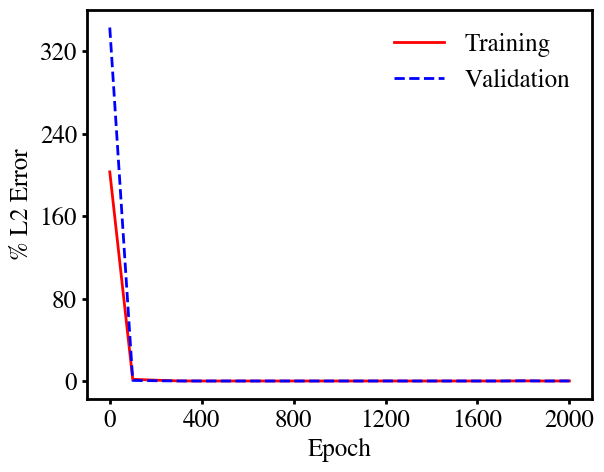

In [36]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs, training_L2_error * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training")
ax.plot(epochs, validation_L2_error * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation")
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.set_xlabel(r"Epoch", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_cnn.pdf")
plt.show()

# Load trained CNN

In [37]:
cnn_model = CNNDiffusionRegressor(training_data.Nx)
cnn_model.load_state_dict(
    torch.load("trained_models/cnn_baseline.pt",
               map_location="cpu", weights_only=True)
)
weights_cnn = cnn_model.network[0].weight.detach().cpu().numpy().ravel()
bias_cnn = cnn_model.network[0].bias.detach().cpu().numpy()
print(f"Weights: {weights_cnn}")
print(f"Bias: {bias_cnn}")

Weights: [0.3999993  0.20000137 0.39999932]
Bias: [8.0224516e-10]


In [38]:
D = 0.4
Fo = D
weights_fdm = np.array([Fo, 1 - 2 * Fo, Fo])
print(f"Finite difference weights: {weights_fdm}")

Finite difference weights: [0.4 0.2 0.4]


# Auto-regressive testing

In [40]:
l2_error_time = {}
mass_err_cnn = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
with torch.inference_mode():
    for init_type in initializations:
        data = np.load(
            "../datasets/training_size_" + str(size) +
            "/testing_data/" + init_type + ".npz"
        )
        u = data["u"]
        u = u[:, np.newaxis, :]
        Nx = data["Nx"]
        snaps = data["snaps"]
        u_tensor = torch.from_numpy(u)
        u_pred_tensor = u_tensor.clone().detach()
        for snap in range(1, u_tensor.shape[0]):
            u_pred_tensor[snap] = cnn_model(
                u_pred_tensor[snap - 1]
            )
        diff = u_pred_tensor.detach().numpy() - u
        l2_error = np.linalg.norm(diff, axis=2) /\
            (np.linalg.norm(u, axis=2) + 1e-10)
        l2_error_time.update({init_type: l2_error})
        u_pred.update(
            {init_type: u_pred_tensor.detach().numpy()}
        )
        u_fdm.update({init_type: u})
        mass_fdm = np.sum(u, axis=2)
        mass_err_fdm.update(
            {init_type: (mass_fdm - mass_fdm[0]) / (mass_fdm[0])}
        )
        mass_cnn = np.sum(u_pred[init_type], axis=2)
        mass_err_cnn.update(
            {init_type: (mass_cnn - mass_cnn[0]) / (mass_cnn[0])}
        )
times = np.arange(0, snaps, 1)  # All must have same time dimension

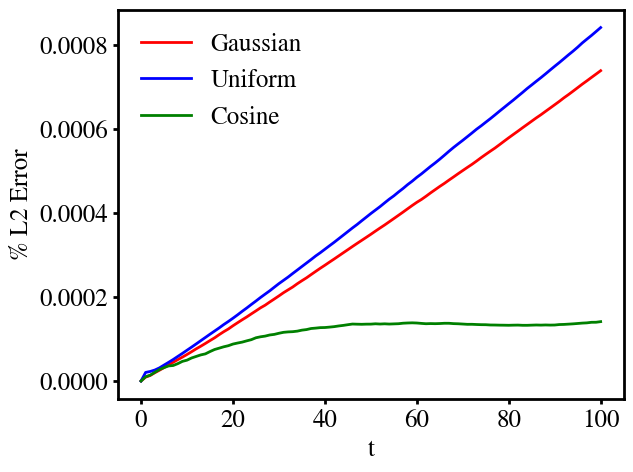

In [41]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, l2_error_time["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian")
ax.plot(times, l2_error_time["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform")
ax.plot(times, l2_error_time["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/autoregressive_cnn.pdf")
plt.show()

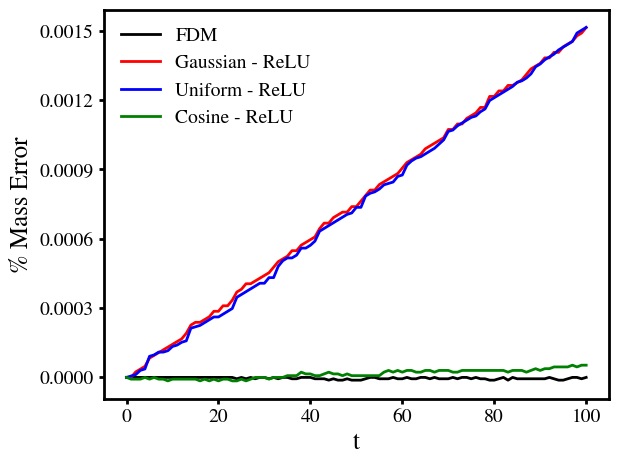

In [42]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, mass_err_fdm["gaussian"] * 100, linewidth=2,
        color="black", linestyle="solid", label=r"FDM")
ax.plot(times, mass_err_cnn["gaussian"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Gaussian - ReLU")
ax.plot(times, mass_err_cnn["uniform"] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Uniform - ReLU")
ax.plot(times, mass_err_cnn["cosine"] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Cosine - ReLU")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% Mass Error", fontsize=18)
ax.tick_params(axis="both", labelsize=14)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=14)
plt.show()

## Unseen - Multimodal Gaussian

In [43]:
l2_error_time = {}
mass_err_cnn = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
with torch.inference_mode():
    for init_type in ["multimodal"]:
        data = np.load("../datasets/training_size_" + str(size) +
                       "/testing_data/" + init_type + ".npz")
        u = data["u"]
        u = u[:, np.newaxis, :]
        Nx = data["Nx"]
        snaps = data["snaps"]
        u_tensor = torch.from_numpy(u)
        u_pred_tensor = u_tensor.clone().detach()
        for snap in range(1, u_tensor.shape[0]):
            u_pred_tensor[snap] = cnn_model(
                u_pred_tensor[snap - 1]
            )
        diff = u_pred_tensor.detach().numpy() - u
        l2_error = np.linalg.norm(diff, axis=2) /\
            (np.linalg.norm(u, axis=2) + 1e-10)
        l2_error_time.update({init_type: l2_error})
        u_pred.update(
            {init_type: u_pred_tensor.detach().numpy()}
        )
        u_fdm.update({init_type: u})
        mass_fdm = np.sum(u, axis=2)
        mass_err_fdm.update(
            {init_type: (mass_fdm - mass_fdm[0]) / (mass_fdm[0])}
        )
        mass_cnn = np.sum(u_pred[init_type], axis=2)
        mass_err_cnn.update(
            {init_type: (mass_cnn - mass_cnn[0]) / (mass_cnn[0])}
        )
times = np.arange(0, snaps, 1)  # All must have same time dimension

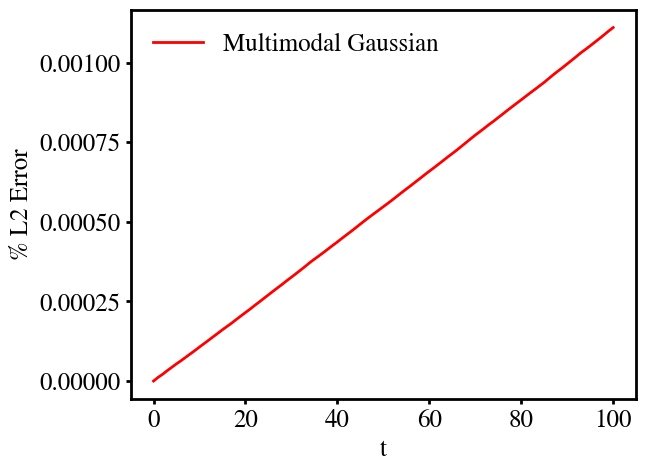

In [44]:
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(times, l2_error_time["multimodal"] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Multimodal Gaussian")
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/autoregressive_cnn_unseen.pdf")
plt.show()